# 01 – Exploratory Data Analysis

**Group:** 119  
**Kaggle team:** [119] SINTEF Databreach  
**Member:** Henrik Remmen (541747)

This notebook covers data quality, temporal coverage, target behaviour, input distributions, train–test drift, and feature–target relationships for the Tokke–Vinje unit-commitment task.


## 1. Setup

Each daily scheduling case covers 168 hours. Target analysis uses only labelled 2015–2022 cases; unlabelled 2023–2024 inputs are used only to analyse covariate shift. Figures are saved to `artifacts/figures/`.


In [1]:
from pathlib import Path
import re
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "artifacts" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 42

print("Project root:", ROOT.resolve())


Project root: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project


## 2. Load and describe all datasets


In [2]:
FILES = {
    "day_ahead_price": DATA_DIR / "kernel" / "Historical_day_ahead_price_2015_2025.csv",
    "historical_inflow": DATA_DIR / "kernel" / "Historical_inflow_1958_2025.csv",
    "historical_volume": DATA_DIR / "kernel" / "Historical_volume_2015_2024.csv",
    "water_value": DATA_DIR / "kernel" / "Synthetic_water_value_2015_2024.csv",
    "unit_commitment": DATA_DIR / "kernel" / "Unit_commitment_decisions.csv",
    "minimum_flow": DATA_DIR / "extended" / "Constraint_min_flow.csv",
    "minimum_volume": DATA_DIR / "extended" / "Constraint_min_volume.csv",
    "prediction_mapping": ROOT / "prediction_mapping.csv",
    "sample_submission": ROOT / "sample_submission.csv",
}

frames = {}
for name, path in FILES.items():
    df = pd.read_csv(path)
    for col in ("date", "starttime"):
        if col in df:
            df[col] = pd.to_datetime(df[col], utc=True)
    frames[name] = df

price = frames["day_ahead_price"]
inflow = frames["historical_inflow"]
volume = frames["historical_volume"]
water_value = frames["water_value"]
unit_commitment = frames["unit_commitment"]
min_flow = frames["minimum_flow"]
min_volume = frames["minimum_volume"]
prediction_mapping = frames["prediction_mapping"]
sample_submission = frames["sample_submission"]

def dominant_frequency(series):
    values = pd.Series(series).dropna().drop_duplicates().sort_values()
    if len(values) < 2:
        return "—"
    step = values.diff().dropna().mode().iloc[0]
    return {pd.Timedelta(minutes=15): "15 minutes",
            pd.Timedelta(hours=1): "Hourly",
            pd.Timedelta(days=1): "Daily"}.get(step, str(step))

rows = []
for name, df in frames.items():
    time_col = next((c for c in ("date", "starttime") if c in df), None)
    rows.append({
        "dataset": name,
        "file": str(FILES[name].relative_to(ROOT)),
        "rows": len(df),
        "columns": len(df.columns),
        "time_period_utc": (
            f"{df[time_col].min():%Y-%m-%d %H:%M} — {df[time_col].max():%Y-%m-%d %H:%M}"
            if time_col else "—"
        ),
        "frequency": dominant_frequency(df[time_col]) if time_col else "—",
        "missing_values": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
    })
dataset_summary = pd.DataFrame(rows)
display(dataset_summary)


,dataset,file,rows,columns,time_period_utc,frequency,missing_values,duplicate_rows
0,day_ahead_price,data/kernel/Historical_day_ahead_price_2015_20...,103062,2,2015-01-01 00:00 — 2025-12-31 23:45,Hourly,0,0
1,historical_inflow,data/kernel/Historical_inflow_1958_2025.csv,594224,19,1958-01-01 00:00 — 2025-10-15 07:00,Hourly,0,0
2,historical_volume,data/kernel/Historical_volume_2015_2024.csv,3654,18,2015-01-01 00:00 — 2025-01-01 00:00,Daily,0,0
3,water_value,data/kernel/Synthetic_water_value_2015_2024.csv,3654,18,2015-01-01 00:00 — 2025-01-01 00:00,Daily,0,0
4,unit_commitment,data/kernel/Unit_commitment_decisions.csv,2922,2355,2015-01-01 00:00 — 2022-12-31 00:00,Daily,0,0
5,minimum_flow,data/extended/Constraint_min_flow.csv,96432,7,2015-01-01 00:00 — 2025-12-31 23:00,Hourly,0,0
6,minimum_volume,data/extended/Constraint_min_volume.csv,96432,4,2015-01-01 00:00 — 2025-12-31 23:00,Hourly,0,0
7,prediction_mapping,prediction_mapping.csv,725,2,2023-01-01 00:00 — 2024-12-25 00:00,Daily,0,0
8,sample_submission,sample_submission.csv,725,2353,—,—,0,0


**Observation.** The data combine hourly price, inflow, and constraint series with daily storage and water-value series. The target file is case-based: each row contains a full one-week schedule. Price changes to 15-minute resolution late in 2025, after the required 2024 horizon, and therefore does not affect this task.


### 2.1 Integrity and coverage checks


In [3]:
timezone_checks = []
for name, df in frames.items():
    for col in ("date", "starttime"):
        if col in df:
            timezone_checks.append({
                "dataset": name, "column": col,
                "timezone": str(df[col].dt.tz),
                "is_utc": str(df[col].dt.tz) == "UTC",
            })
display(pd.DataFrame(timezone_checks))

id_checks = pd.DataFrame([{
    "dataset": name,
    "rows": len(frames[name]),
    "unique_Run_No": frames[name]["Run No"].nunique(),
    "duplicate_Run_No": frames[name]["Run No"].duplicated().sum(),
    "is_unique": frames[name]["Run No"].is_unique,
} for name in ("unit_commitment", "prediction_mapping", "sample_submission")])
display(id_checks)

pattern = re.compile(r"^result_committed_(.+)_t(\d+)$")
target_meta = [(c, pattern.match(c).group(1), int(pattern.match(c).group(2)))
               for c in unit_commitment.columns if pattern.match(c)]
target_columns = [x[0] for x in target_meta]
units = list(dict.fromkeys(x[1] for x in target_meta))
horizons = {u: sorted(x[2] for x in target_meta if x[1] == u) for u in units}
target_values = np.unique(unit_commitment[target_columns].to_numpy())

structure = pd.DataFrame({
    "unit": units,
    "target_columns": [len(horizons[u]) for u in units],
    "first_t": [min(horizons[u]) for u in units],
    "last_t": [max(horizons[u]) for u in units],
    "complete_t0_t167": [horizons[u] == list(range(168)) for u in units],
})
print("Unique target values:", target_values.tolist())
display(structure)

mapping_dates = prediction_mapping["starttime"].sort_values()
display(pd.DataFrame([{
    "mapping_rows": len(mapping_dates),
    "first_case": mapping_dates.min(),
    "last_case": mapping_dates.max(),
    "contains_2023": (mapping_dates.dt.year == 2023).any(),
    "contains_2024": (mapping_dates.dt.year == 2024).any(),
    "daily_without_gaps": len(mapping_dates) == len(pd.date_range(
        mapping_dates.min(), mapping_dates.max(), freq="D", tz="UTC")),
}]))

assert pd.DataFrame(timezone_checks)["is_utc"].all()
assert id_checks["is_unique"].all()
assert set(target_values).issubset({0, 1})
assert len(units) == 14
assert all(horizons[u] == list(range(168)) for u in units)
assert target_columns == list(sample_submission.columns[1:])


,dataset,column,timezone,is_utc
0,day_ahead_price,date,UTC,True
1,historical_inflow,date,UTC,True
2,historical_volume,date,UTC,True
3,water_value,date,UTC,True
4,unit_commitment,starttime,UTC,True
5,minimum_flow,date,UTC,True
6,minimum_volume,date,UTC,True
7,prediction_mapping,starttime,UTC,True


,dataset,rows,unique_Run_No,duplicate_Run_No,is_unique
0,unit_commitment,2922,2922,0,True
1,prediction_mapping,725,725,0,True
2,sample_submission,725,725,0,True


Unique target values: [0, 1]


,unit,target_columns,first_t,last_t,complete_t0_t167
0,Hogga_G1,168,0,167,True
1,Tokke_G1,168,0,167,True
2,Tokke_G2,168,0,167,True
3,Tokke_G3,168,0,167,True
4,Tokke_G4,168,0,167,True
5,Lio_G1,168,0,167,True
6,Byrte_G1,168,0,167,True
7,Vinje_G1,168,0,167,True
8,Vinje_G2,168,0,167,True
9,Vinje_G3,168,0,167,True


,mapping_rows,first_case,last_case,contains_2023,contains_2024,daily_without_gaps
0,725,2023-01-01 00:00:00+00:00,2024-12-25 00:00:00+00:00,True,True,True


In [4]:
train_starts = pd.DatetimeIndex(unit_commitment["starttime"])
test_starts = pd.DatetimeIndex(prediction_mapping["starttime"])
all_starts = train_starts.append(test_starts).sort_values()
expected_hourly = pd.date_range(all_starts.min(),
                                all_starts.max() + pd.Timedelta(hours=167),
                                freq="h", tz="UTC")
expected_starts = pd.DatetimeIndex(all_starts.unique()).sort_values()
expected_ends = expected_starts + pd.Timedelta(days=7)

def coverage_row(name, df, expected):
    available = pd.DatetimeIndex(df["date"].dropna().unique()).sort_values()
    missing = expected.difference(available)
    return {"dataset": name, "required": len(expected),
            "missing": len(missing), "complete": len(missing) == 0,
            "first_missing": missing[0] if len(missing) else "—"}

coverage = pd.DataFrame([
    coverage_row("price: complete horizon", price, expected_hourly),
    coverage_row("inflow: complete horizon", inflow, expected_hourly),
    coverage_row("minimum flow: complete horizon", min_flow, expected_hourly),
    coverage_row("minimum volume: complete horizon", min_volume, expected_hourly),
    coverage_row("storage: case start", volume, expected_starts),
    coverage_row("water value: case end +7 days", water_value, expected_ends),
])
display(coverage)
assert coverage["complete"].all()


,dataset,required,missing,complete,first_missing
0,price: complete horizon,87672,0,True,—
1,inflow: complete horizon,87672,0,True,—
2,minimum flow: complete horizon,87672,0,True,—
3,minimum volume: complete horizon,87672,0,True,—
4,storage: case start,3647,0,True,—
5,water value: case end +7 days,3647,0,True,—


**Integrity conclusion.** All time columns are UTC, all three `Run No` columns are unique, every target is 0 or 1, and all 14 units have exactly 168 targets. The mapping contains 725 consecutive cases from 2023-01-01 through 2024-12-25, and every input covers the complete required week horizons.


## 3. Target analysis

The target cube has dimensions `case × unit × horizon hour`. Month and hour use the actual target timestamp `starttime + t`; annual comparisons use the scheduling-case start year.


In [5]:
target_cube = np.stack([
    unit_commitment[[f"result_committed_{u}_t{h}" for h in range(168)]]
    .to_numpy(dtype=np.int8)
    for u in units
], axis=1)

target_time_index = pd.DatetimeIndex(
    train_starts.repeat(168)
    + pd.to_timedelta(np.tile(np.arange(168), len(train_starts)), unit="h")
)
target_month = target_time_index.month.to_numpy().reshape(len(train_starts), 168)
target_hour = target_time_index.hour.to_numpy().reshape(len(train_starts), 168)
case_hour_targets = target_cube.transpose(0, 2, 1).reshape(-1, len(units))
print("Target cube shape:", target_cube.shape)


Target cube shape: (2922, 14, 168)


### 3.1 ON-rate per generator


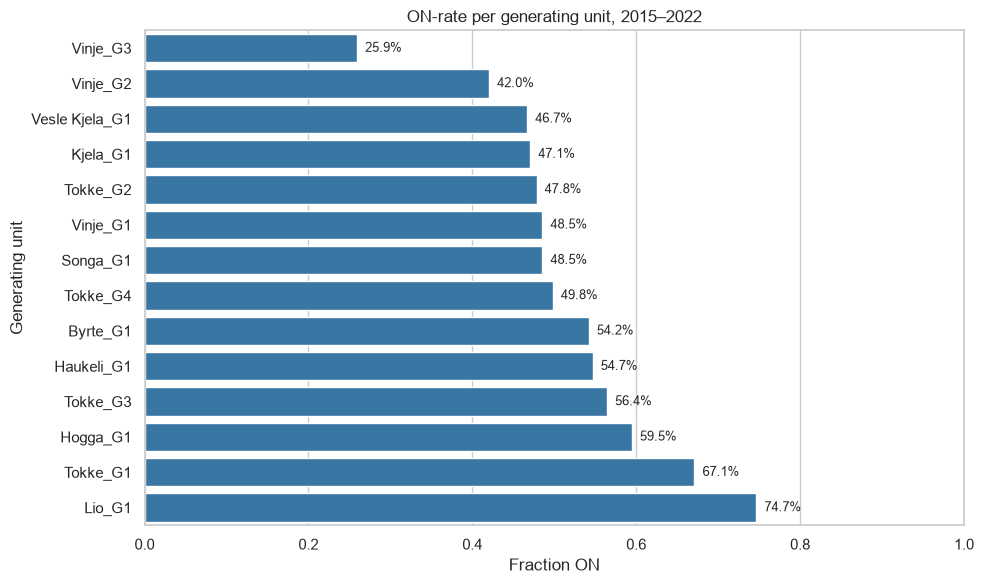

In [6]:
unit_rate = pd.Series(target_cube.mean(axis=(0, 2)), index=units).sort_values()
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=unit_rate.values, y=unit_rate.index, color="#2878B5", ax=ax)
ax.set(xlabel="Fraction ON", ylabel="Generating unit",
       title="ON-rate per generating unit, 2015–2022", xlim=(0, 1))
for i, value in enumerate(unit_rate):
    ax.text(value + .01, i, f"{value:.1%}", va="center", fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR/"target_on_rate_by_unit.png", dpi=160); plt.show()


**Observation.** Lio_G1 is ON about 74.7% of the time, while Vinje_G3 is ON only about 25.9%. Per-unit models or a shared model with generator identity must account for these different base rates.


### 3.2 ON-rate per generator and year


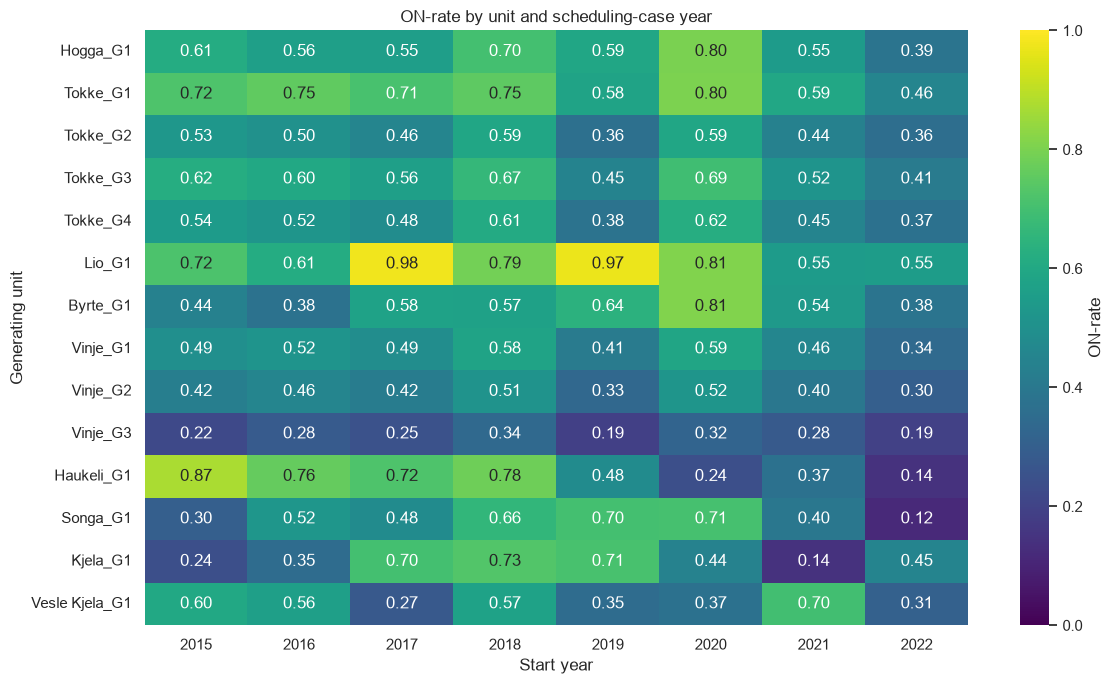

In [7]:
years = train_starts.year
year_unit = pd.DataFrame({
    year: target_cube[years == year].mean(axis=(0, 2))
    for year in sorted(np.unique(years))
}, index=units)
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(year_unit, annot=True, fmt=".2f", cmap="viridis",
            vmin=0, vmax=1, cbar_kws={"label": "ON-rate"}, ax=ax)
ax.set(title="ON-rate by unit and scheduling-case year",
       xlabel="Start year", ylabel="Generating unit")
fig.tight_layout(); fig.savefig(FIG_DIR/"target_on_rate_unit_year.png", dpi=160); plt.show()


**Observation.** Operating regimes vary strongly by year. Haukeli_G1 falls from about 87% ON in 2015 to 14% in 2022, and many other units also decline in 2022. Random validation would mix these regimes and overestimate future performance.


### 3.3 ON-rate per calendar month


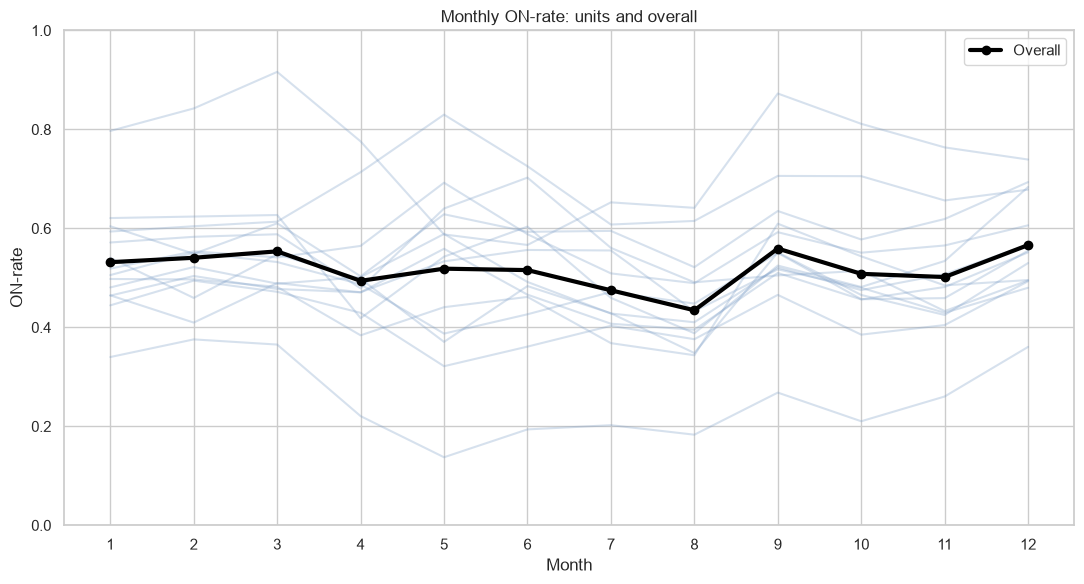

In [8]:
month_unit = pd.DataFrame(index=range(1, 13), columns=units, dtype=float)
for month in month_unit.index:
    mask = target_month == month
    for i, unit in enumerate(units):
        month_unit.loc[month, unit] = target_cube[:, i, :][mask].mean()
fig, ax = plt.subplots(figsize=(11, 6))
for unit in units:
    ax.plot(month_unit.index, month_unit[unit], color="#7A9CC6", alpha=.3)
ax.plot(month_unit.index, month_unit.mean(axis=1), color="black",
        linewidth=3, marker="o", label="Overall")
ax.set(xticks=range(1,13), xlabel="Month", ylabel="ON-rate",
       title="Monthly ON-rate: units and overall", ylim=(0,1)); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR/"target_on_rate_by_month.png", dpi=160); plt.show()


**Observation.** Overall operation is lowest in August (about 43.5%) and highest in December (about 56.6%). Unit-level curves vary, so seasonal features should interact with unit identity and hydrological state.


### 3.4 ON-rate per hour of day


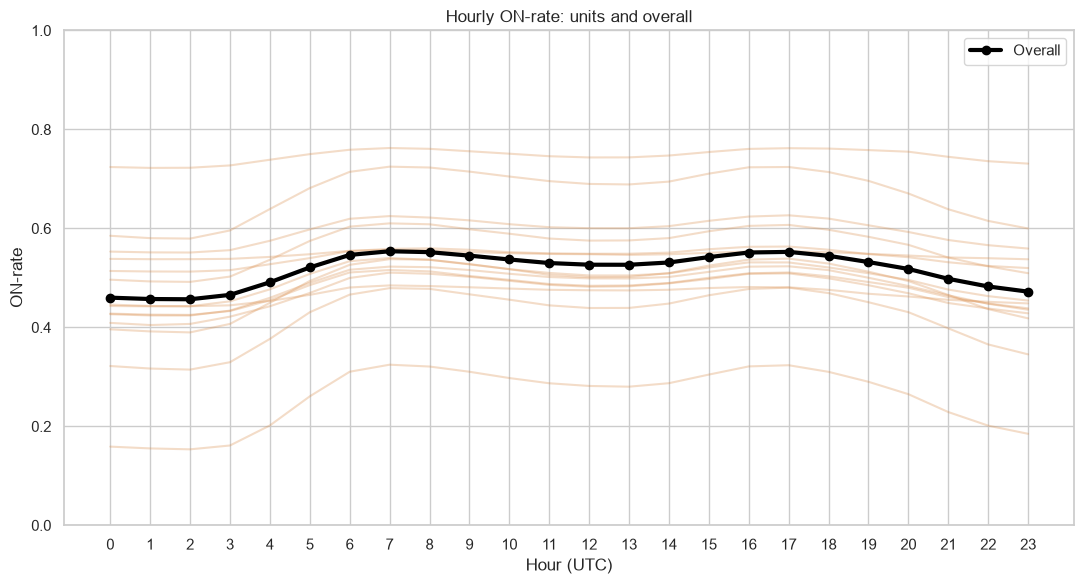

In [9]:
hour_unit = pd.DataFrame(index=range(24), columns=units, dtype=float)
for hour in hour_unit.index:
    mask = target_hour == hour
    for i, unit in enumerate(units):
        hour_unit.loc[hour, unit] = target_cube[:, i, :][mask].mean()
fig, ax = plt.subplots(figsize=(11, 6))
for unit in units:
    ax.plot(hour_unit.index, hour_unit[unit], color="#D98C4A", alpha=.3)
ax.plot(hour_unit.index, hour_unit.mean(axis=1), color="black",
        linewidth=3, marker="o", label="Overall")
ax.set(xticks=range(24), xlabel="Hour (UTC)", ylabel="ON-rate",
       title="Hourly ON-rate: units and overall", ylim=(0,1)); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR/"target_on_rate_by_hour.png", dpi=160); plt.show()


**Observation.** ON-rate is lowest around 00:00–03:00 UTC (roughly 46%) and reaches about 55% near the morning and evening peaks. Cyclic hour features and price–hour interactions are justified.


### 3.5 ON-rate through `t0–t167`


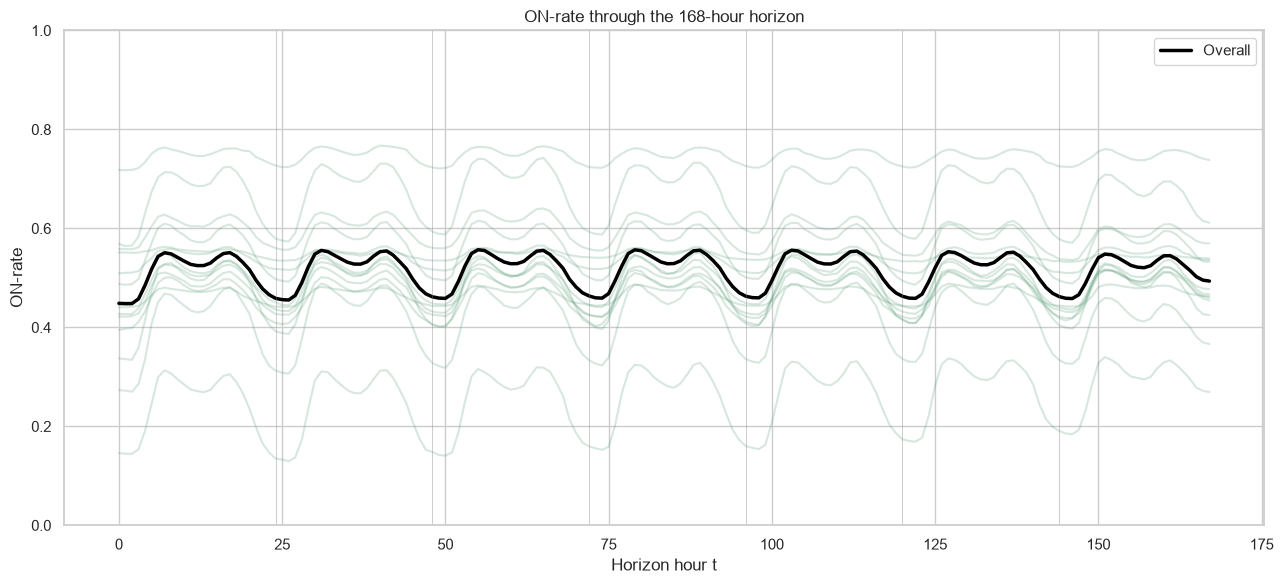

In [10]:
horizon_unit = pd.DataFrame(target_cube.mean(axis=0).T,
                                index=range(168), columns=units)
fig, ax = plt.subplots(figsize=(13, 6))
for unit in units:
    ax.plot(horizon_unit.index, horizon_unit[unit], color="#4C956C", alpha=.22)
ax.plot(horizon_unit.index, horizon_unit.mean(axis=1),
        color="black", linewidth=2.5, label="Overall")
for x in range(24, 168, 24):
    ax.axvline(x, color="grey", linewidth=.7, alpha=.4)
ax.set(xlabel="Horizon hour t", ylabel="ON-rate",
       title="ON-rate through the 168-hour horizon", ylim=(0,1)); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR/"target_on_rate_by_horizon.png", dpi=160); plt.show()


**Observation.** The global daily averages remain close to 51–52% through the week. Horizon position alone is weak, but its repeating daily pattern and unit-specific effects support adding `t`, hour, and day-within-horizon features.


### 3.6 Correlation between generators


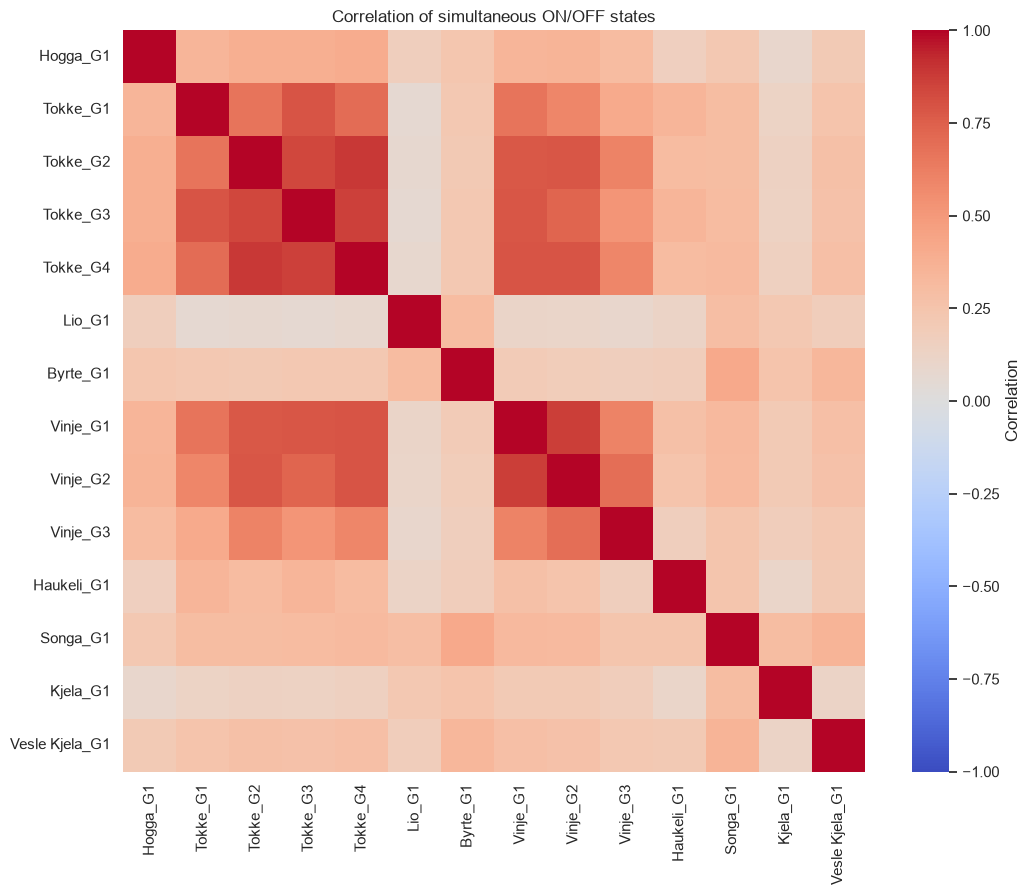

,,correlation
Tokke_G2,Tokke_G4,0.886367
Vinje_G1,Vinje_G2,0.874089
Tokke_G3,Tokke_G4,0.863897
Tokke_G2,Tokke_G3,0.839026
Tokke_G4,Vinje_G1,0.795479
Tokke_G1,Tokke_G3,0.794684
Tokke_G4,Vinje_G2,0.792906
Tokke_G2,Vinje_G2,0.788815
Tokke_G3,Vinje_G1,0.785711
Tokke_G2,Vinje_G1,0.778234


In [11]:
corr = pd.DataFrame(case_hour_targets, columns=units).corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"label":"Correlation"}, ax=ax)
ax.set_title("Correlation of simultaneous ON/OFF states")
fig.tight_layout(); fig.savefig(FIG_DIR/"target_unit_correlation.png", dpi=160); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
display(upper.head(10).rename("correlation").to_frame())


**Observation.** Units in the same multi-generator plants are strongly dependent: Tokke_G2–Tokke_G4 correlate around 0.89 and Vinje_G1–Vinje_G2 around 0.87. A shared or second-stage model can exploit these simultaneous relationships.


### 3.7 Consecutive ON/OFF-periods


,count,mean,std,min,25%,50%,75%,90%,95%,max
state,,,,,,,,,,
OFF,64047.0,51.89,62.11,1.0,6.0,16.0,85.0,168.0,168.0,168.0
ON,61675.0,57.54,65.53,1.0,7.0,18.0,117.0,168.0,168.0,168.0


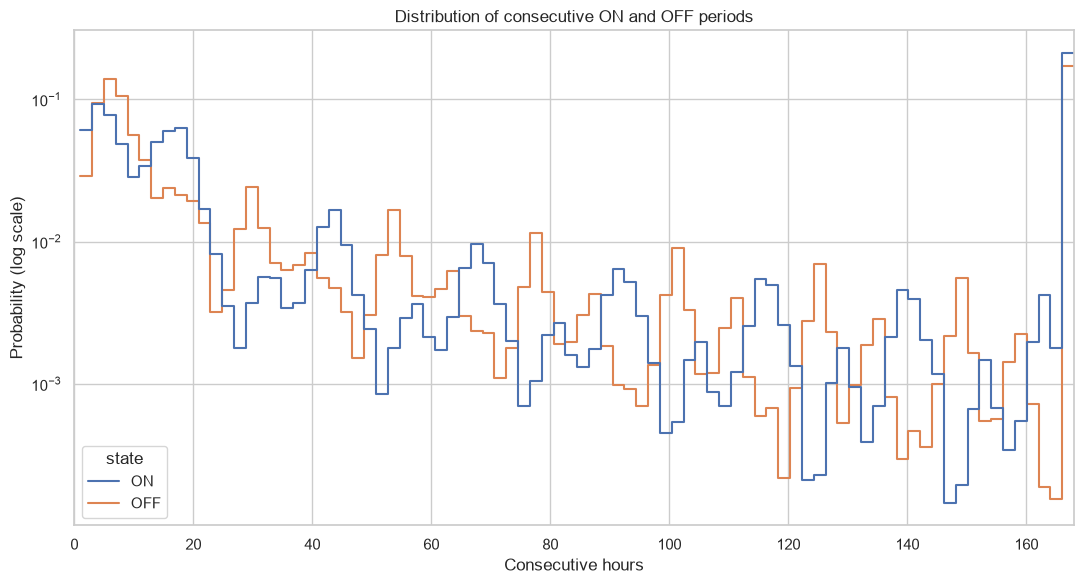

In [12]:
runs = []
for sequence, unit in zip(
    target_cube.reshape(-1, 168),
    np.tile(np.repeat(units, 1), target_cube.shape[0])
):
    bounds = np.r_[0, np.flatnonzero(sequence[1:] != sequence[:-1]) + 1, 168]
    for state, length in zip(sequence[bounds[:-1]], np.diff(bounds)):
        runs.append((unit, "ON" if state else "OFF", int(length)))
run_lengths = pd.DataFrame(runs, columns=["unit", "state", "length"])
display(run_lengths.groupby("state")["length"].describe(
    percentiles=[.25,.5,.75,.9,.95]).round(2))
fig, ax = plt.subplots(figsize=(11, 6))
sns.histplot(data=run_lengths, x="length", hue="state", stat="probability",
             common_norm=False, binwidth=2, element="step", fill=False,
             log_scale=(False, True), ax=ax)
ax.set(xlabel="Consecutive hours", ylabel="Probability (log scale)",
       title="Distribution of consecutive ON and OFF periods", xlim=(0,168))
fig.tight_layout(); fig.savefig(FIG_DIR/"target_run_lengths.png", dpi=160); plt.show()


**Observation.** Median OFF and ON periods are approximately 16 and 18 hours, while many cases remain in one state for all 168 hours. This persistence motivates rolling-window features and a sequence model, provided improvements are verified with ROC-AUC.


## 4. Input-data analysis

Hourly inputs are aggregated to daily values for comparable figures. Water value is averaged across reservoirs; volume, inflow, and constraint quantities are summed across the system.


/var/folders/bj/190d2f4s35v16y9k7csnjkl40000gn/T/ipykernel_44613/3821660212.py:4: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  daily = pd.concat({


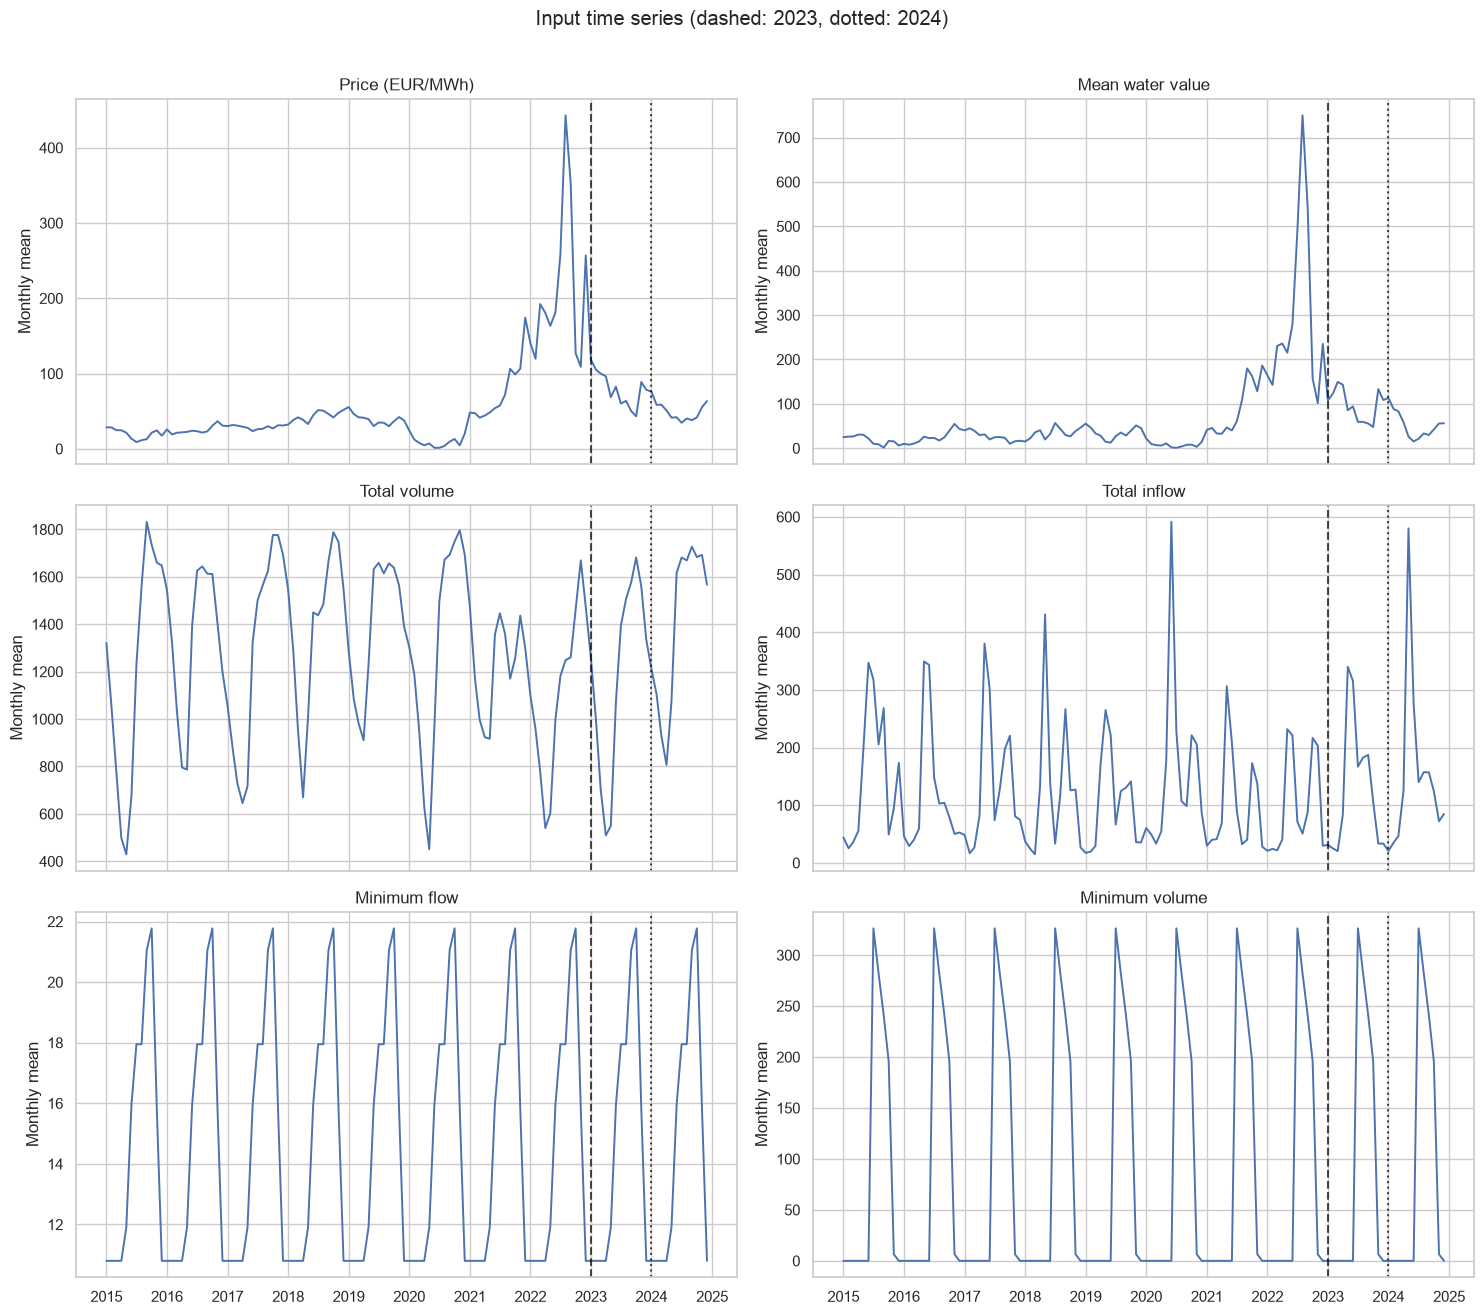

In [13]:
def numeric_indexed(df):
    return df.set_index("date").select_dtypes(include=np.number)

daily = pd.concat({
    "Price (EUR/MWh)": price.set_index("date")["Day-ahead price (EUR/MWh)"].resample("D").mean(),
    "Mean water value": numeric_indexed(water_value).mean(axis=1),
    "Total volume": numeric_indexed(volume).sum(axis=1),
    "Total inflow": numeric_indexed(inflow).sum(axis=1).resample("D").mean(),
    "Minimum flow": numeric_indexed(min_flow).sum(axis=1).resample("D").mean(),
    "Minimum volume": numeric_indexed(min_volume).sum(axis=1).resample("D").mean(),
}, axis=1).sort_index().loc["2015-01-01":"2024-12-31"]

monthly = daily.resample("MS").mean()
fig, axes = plt.subplots(3, 2, figsize=(15, 13), sharex=True)
for ax, col in zip(axes.flat, monthly.columns):
    ax.plot(monthly.index, monthly[col], linewidth=1.4)
    ax.set_title(col); ax.set_ylabel("Monthly mean")
    ax.axvline(pd.Timestamp("2023-01-01", tz="UTC"), color="black", ls="--", alpha=.7)
    ax.axvline(pd.Timestamp("2024-01-01", tz="UTC"), color="black", ls=":", alpha=.7)
fig.suptitle("Input time series (dashed: 2023, dotted: 2024)", y=1.01)
fig.tight_layout(); fig.savefig(FIG_DIR/"inputs_monthly_timeseries.png", dpi=160); plt.show()


**Observation.** Price and water value move through very different regimes, with low values in 2020 and extreme values in 2022. Volume, inflow, and constraints show strong seasonality. Models should use current physical conditions and relative temporal features rather than memorising calendar years.


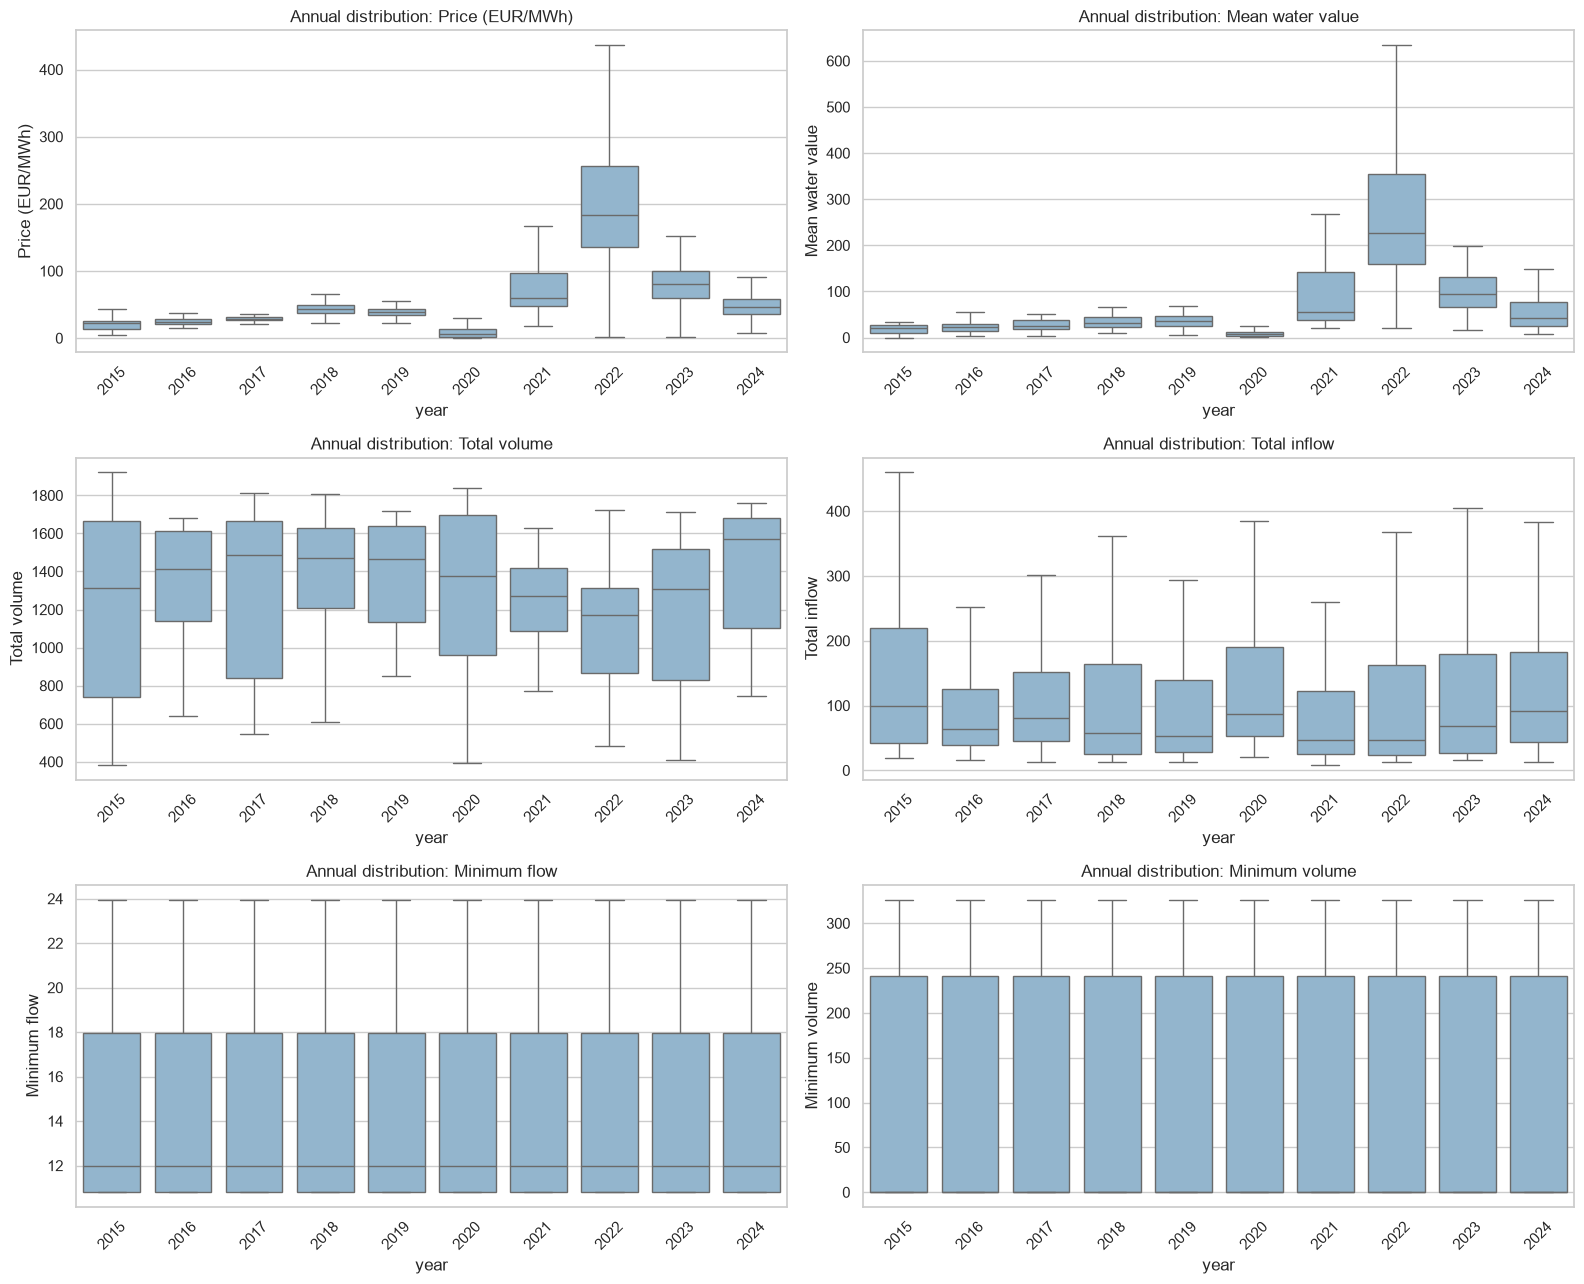

Price (EUR/MWh)               Mean water value                Total volume                  Total inflow                Minimum flow         \
                           mean median    std             mean median     std         mean   median     std         mean median     std         mean median   
period                                                                                                                                                        
Private 2024              50.12  46.64  27.17            51.91  42.77   32.83      1397.78  1572.51  338.93       152.23  91.47  165.56        14.71   12.0   
Public 2023               79.44  81.21  31.87            96.99  94.55   41.25      1179.72  1305.46  402.14       127.68  67.94  139.84        14.72   12.0   
Train 2015–2022           56.47  31.70  76.15            66.47  29.18  117.68      1278.12  1348.49  377.12       124.41  65.89  146.26        14.71   12.0   

                      Minimum volume                 
                  std           mean median     std  
period                                               
Private 2024     4.44          88.39    0.0  127.49  
Public 2023      4.44          88.63    0.0  127.58  
Train 2015–2022  4.43          88.57    0.0  127.41

In [14]:
daily_plot = daily.reset_index(names="date")
daily_plot["year"] = daily_plot["date"].dt.year
fig, axes = plt.subplots(3, 2, figsize=(16, 13))
for ax, col in zip(axes.flat, daily.columns):
    sns.boxplot(data=daily_plot, x="year", y=col, showfliers=False,
                color="#8AB6D6", ax=ax)
    ax.set_title(f"Annual distribution: {col}")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout(); fig.savefig(FIG_DIR/"inputs_annual_distributions.png", dpi=160); plt.show()

daily_plot["period"] = np.select(
    [daily_plot.year <= 2022, daily_plot.year == 2023, daily_plot.year == 2024],
    ["Train 2015–2022", "Public 2023", "Private 2024"], default="Other")
period_summary = daily_plot[daily_plot.period != "Other"].groupby("period")[
    list(daily.columns)].agg(["mean", "median", "std"]).round(2)
display(period_summary)


**Observation.** Private-year 2024 is not a continuation of 2022: its prices and water values are much lower, while system storage is substantially higher. Model selection should use several chronological folds and reward robust relative features, not only performance on the latest training year.


## 5. Feature–target relationships

Values are aligned to each target hour. Water value is taken at the end of the seven-day horizon, as specified by the data documentation. Filling ratio is case-start total storage divided by total maximum storage from the supplied topology.


In [15]:
price_matrix = price.set_index("date")["Day-ahead price (EUR/MWh)"].reindex(
    target_time_index).to_numpy().reshape(len(train_starts), 168)
inflow_matrix = numeric_indexed(inflow).sum(axis=1).reindex(
    target_time_index).to_numpy().reshape(len(train_starts), 168)
final_dates = train_starts + pd.Timedelta(days=7)
case_water_value = numeric_indexed(water_value).reindex(final_dates).mean(axis=1).to_numpy()

with open(DATA_DIR/"extended"/"Tokke_Vinje_topology.yaml") as stream:
    topology = yaml.safe_load(stream)
capacities = {name: values["max_vol"]
              for name, values in topology["model"]["reservoir"].items()}
volume_cols = [c for c in volume if c != "date"]
total_capacity = sum(capacities[c] for c in volume_cols)
case_volume = numeric_indexed(volume).reindex(train_starts)[volume_cols].sum(axis=1).to_numpy()
case_fill = case_volume / total_capacity

price_rank = pd.DataFrame(price_matrix).rank(axis=1, pct=True).to_numpy()
margin = price_matrix - case_water_value[:, None]
fill_matrix = np.broadcast_to(case_fill[:, None], price_matrix.shape)

def varying_active(df):
    positive = numeric_indexed(df) > 0
    rate = positive.mean()
    columns = rate[(rate > 0) & (rate < 1)].index.tolist()
    return positive[columns].any(axis=1), columns

flow_active, variable_flow_cols = varying_active(min_flow)
volume_active, variable_volume_cols = varying_active(min_volume)
constraint_active = (
    flow_active.reindex(target_time_index, fill_value=False).to_numpy()
    | volume_active.reindex(target_time_index, fill_value=False).to_numpy()
).reshape(len(train_starts), 168)

print("Variable flow constraints:", variable_flow_cols)
print("Variable volume constraints:", variable_volume_cols)
print(f"Variable constraints active in {constraint_active.mean():.1%} of target hours")
assert all(np.isfinite(x).all() for x in
           (price_matrix, inflow_matrix, case_water_value, case_fill))


Variable flow constraints: ['b_Byrtevatn']
Variable volume constraints: ['Totak', 'Byrtevatn', 'Staavatn']
Variable constraints active in 46.8% of target hours


In [16]:
feature_matrices = {
    "Raw price": price_matrix,
    "Within-week price percentile": price_rank,
    "Price minus final water value": margin,
    "System filling ratio": fill_matrix,
    "Total inflow": inflow_matrix,
}

def quantile_rates(matrix, name):
    x = matrix.ravel()
    valid = np.isfinite(x)
    edges = np.unique(np.quantile(x[valid], np.linspace(0, 1, 11)))
    bins = np.digitize(x, edges[1:-1], right=True)
    out = []
    for b in range(len(edges)-1):
        mask = valid & (bins == b)
        out.append((name, b+1, "Overall", case_hour_targets[mask].mean()))
        for i, unit in enumerate(units):
            out.append((name, b+1, unit, case_hour_targets[mask, i].mean()))
    return pd.DataFrame(out, columns=["feature","bin","unit","on_rate"])

rates = pd.concat([quantile_rates(x, name)
                   for name, x in feature_matrices.items()], ignore_index=True)
constraint_flat = constraint_active.ravel()
constraint_rows = []
for active in (False, True):
    mask = constraint_flat == active
    constraint_rows.append(("Active" if active else "Inactive",
                            "Overall", case_hour_targets[mask].mean()))
    for i, unit in enumerate(units):
        constraint_rows.append(("Active" if active else "Inactive",
                                unit, case_hour_targets[mask, i].mean()))
constraint_rates = pd.DataFrame(constraint_rows,
                                columns=["state","unit","on_rate"])

display(rates[rates.unit=="Overall"].pivot(
    index="bin", columns="feature", values="on_rate").round(3))
display(constraint_rates[constraint_rates.unit=="Overall"].set_index("state").round(3))


feature,Price minus final water value,Raw price,System filling ratio,Total inflow,Within-week price percentile
bin,,,,,
1,0.168,0.495,0.418,0.464,0.382
2,0.256,0.640,0.435,0.503,0.431
3,0.302,0.550,0.537,0.493,0.462
4,0.376,0.549,0.471,0.460,0.485
5,0.512,0.516,0.432,0.498,0.507
6,0.570,0.516,0.469,0.491,0.526
7,0.637,0.563,0.568,0.534,0.548
8,0.698,0.577,0.543,0.591,0.572
9,0.780,0.379,0.577,0.558,0.602


,unit,on_rate
state,,
Inactive,Overall,0.529
Active,Overall,0.503


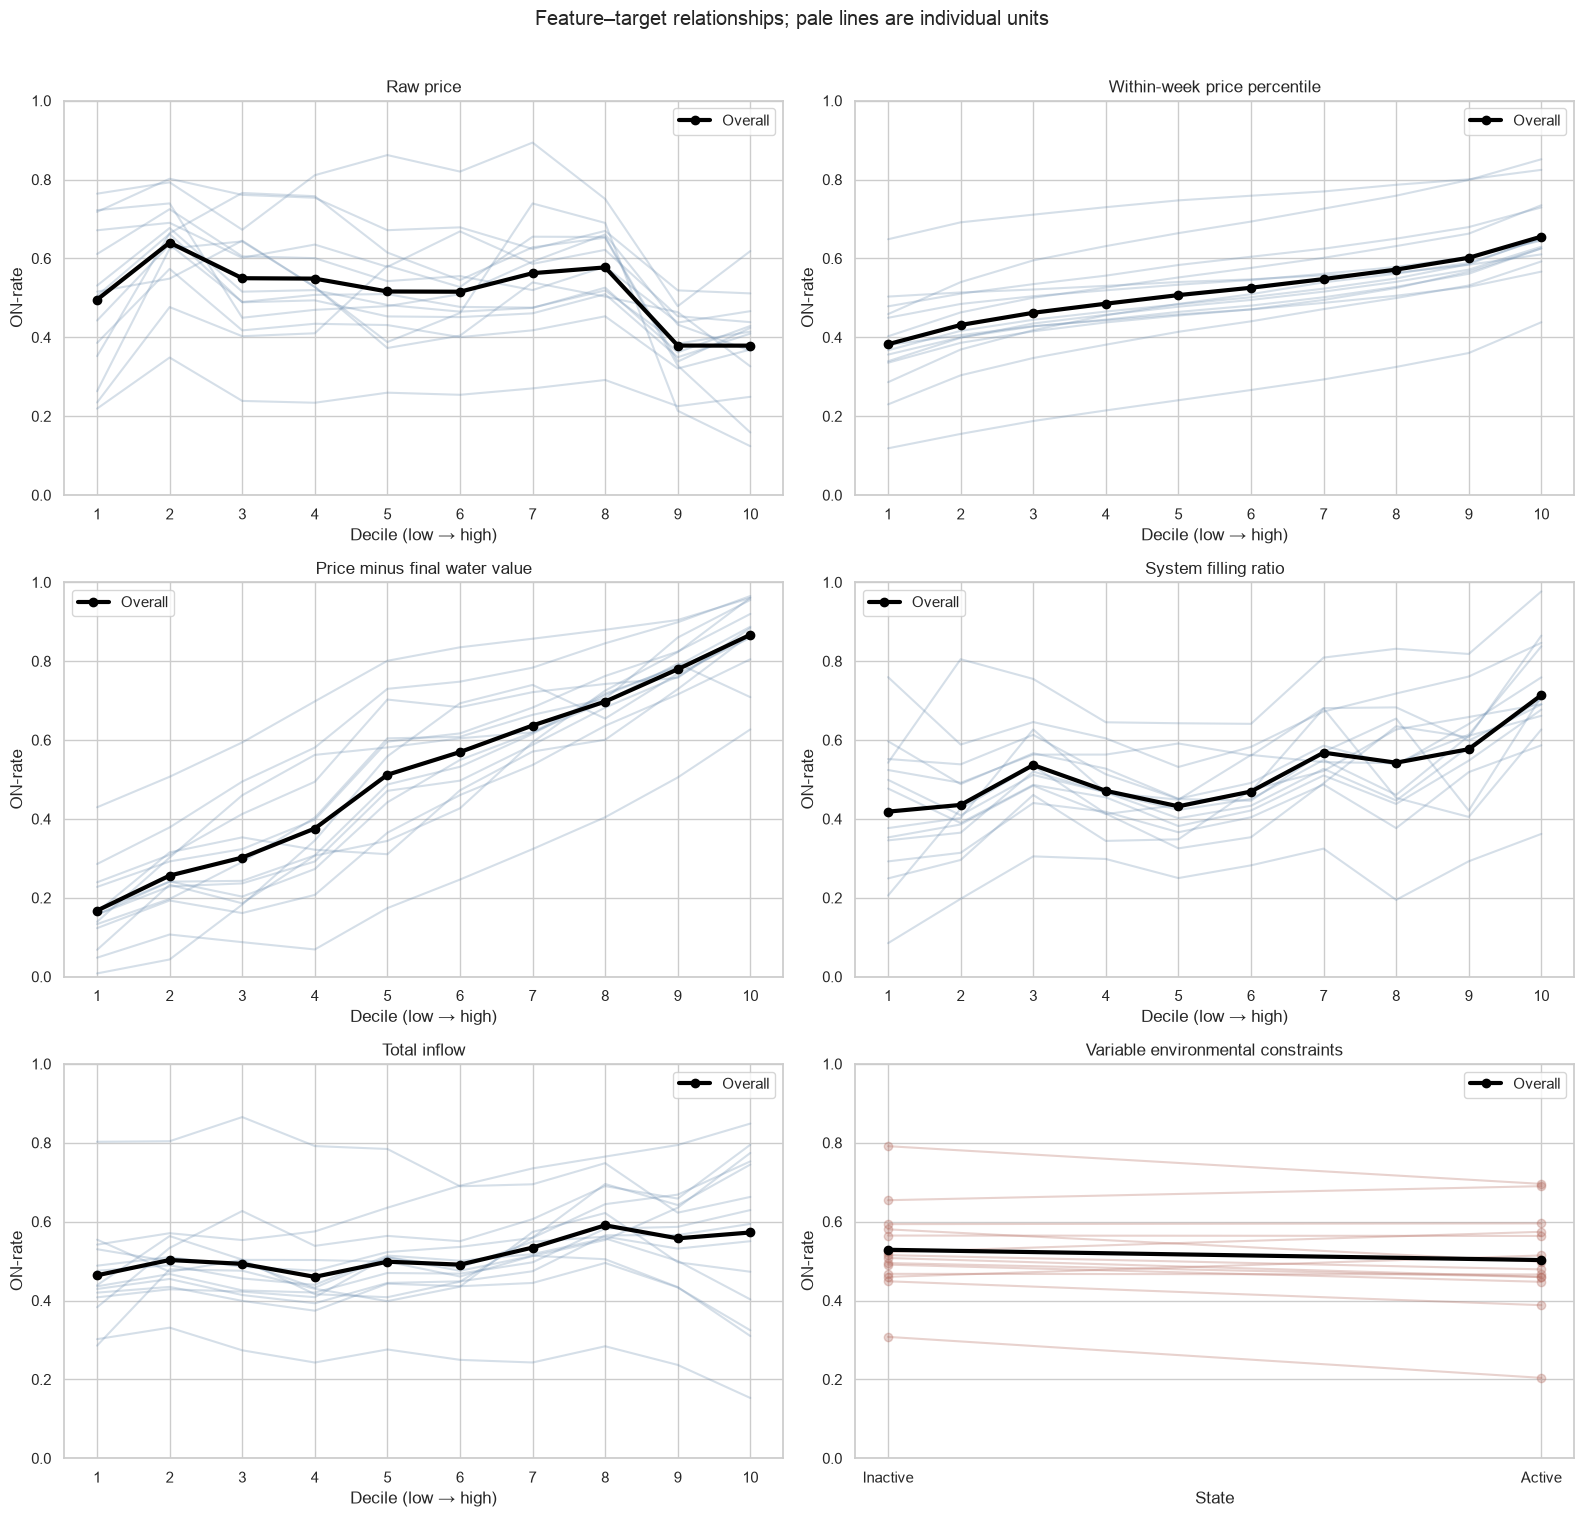

In [17]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
for ax, name in zip(axes.flat[:5], feature_matrices):
    data = rates[rates.feature == name]
    for unit in units:
        d = data[data.unit == unit]
        ax.plot(d.bin, d.on_rate, color="#6A8CAF", alpha=.28)
    d = data[data.unit == "Overall"]
    ax.plot(d.bin, d.on_rate, color="black", linewidth=3, marker="o", label="Overall")
    ax.set(title=name, xlabel="Decile (low → high)", ylabel="ON-rate",
           ylim=(0,1), xticks=range(1,11)); ax.legend()
ax = axes.flat[5]
for unit in units:
    d = constraint_rates[constraint_rates.unit == unit]
    ax.plot([0,1], d.on_rate, color="#B36A5E", alpha=.3, marker="o")
d = constraint_rates[constraint_rates.unit == "Overall"]
ax.plot([0,1], d.on_rate, color="black", linewidth=3, marker="o", label="Overall")
ax.set(title="Variable environmental constraints", xlabel="State",
       ylabel="ON-rate", xticks=[0,1], xticklabels=["Inactive","Active"], ylim=(0,1))
ax.legend()
fig.suptitle("Feature–target relationships; pale lines are individual units", y=1.01)
fig.tight_layout(); fig.savefig(FIG_DIR/"feature_target_relationships.png", dpi=160); plt.show()


**Observation.** Raw price is non-monotonic because annual regimes differ. Within-week price percentile rises consistently from about 38% ON in the lowest decile to 65% in the highest, while `price − water value` rises from roughly 17% to 87%. Filling, inflow, and environmental constraints are nonlinear and unit-dependent, which favours tree models and preserving the individual constraint columns.


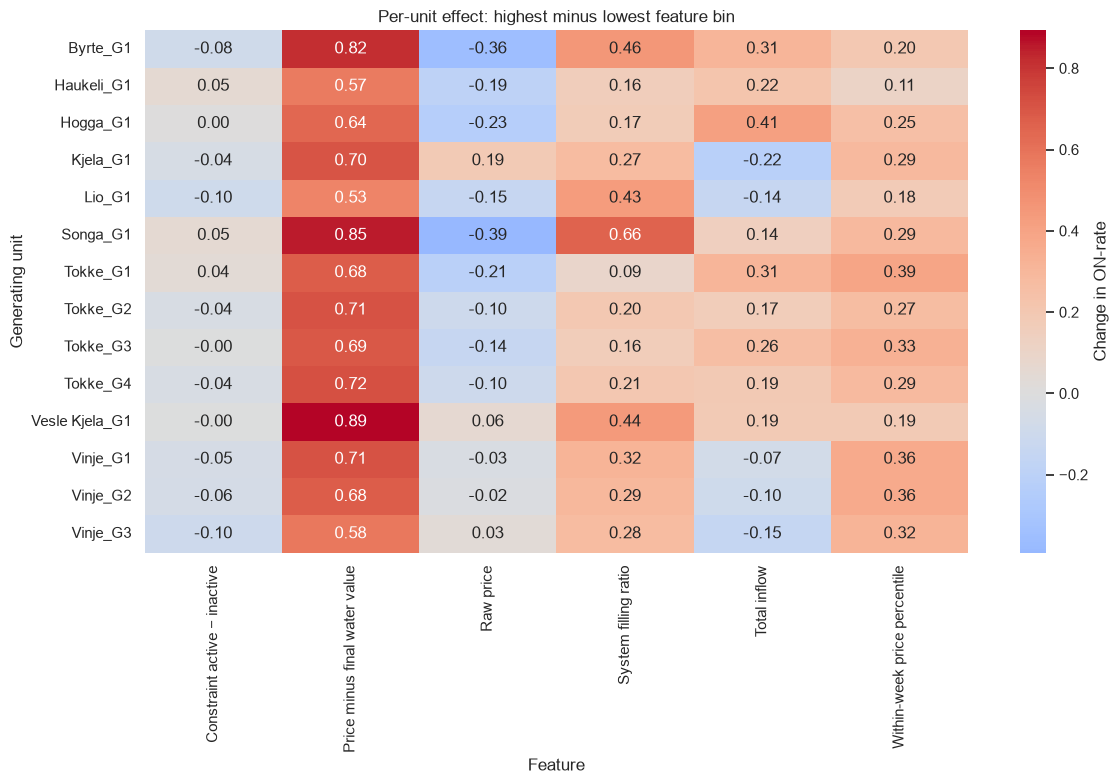

In [18]:
effects = []
for name in feature_matrices:
    d = rates[(rates.feature == name) & (rates.unit != "Overall")]
    low = d.sort_values("bin").groupby("unit").first().on_rate
    high = d.sort_values("bin").groupby("unit").last().on_rate
    effects.extend((unit, name, high[unit]-low[unit]) for unit in units)
inactive = constraint_rates[(constraint_rates.state=="Inactive") &
                            (constraint_rates.unit!="Overall")].set_index("unit").on_rate
active = constraint_rates[(constraint_rates.state=="Active") &
                          (constraint_rates.unit!="Overall")].set_index("unit").on_rate
effects.extend((unit, "Constraint active − inactive", active[unit]-inactive[unit])
               for unit in units)
effect_table = pd.DataFrame(effects, columns=["unit","feature","effect"]).pivot(
    index="unit", columns="feature", values="effect")
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(effect_table, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            cbar_kws={"label":"Change in ON-rate"}, ax=ax)
ax.set(title="Per-unit effect: highest minus lowest feature bin",
       xlabel="Feature", ylabel="Generating unit")
fig.tight_layout(); fig.savefig(FIG_DIR/"feature_effects_by_unit.png", dpi=160); plt.show()


**Observation.** The heatmap confirms that the same system-level condition can affect generators differently. This argues against a single undifferentiated classifier unless it contains generator identity, static plant properties, and interactions; per-unit LightGBM remains the safest first strong model.


## 6. Conclusions and modelling hypotheses

| EDA observation | Hypothesis | Planned feature or experiment |
|---|---|---|
| Base ON-rates differ strongly by unit | Units have different thresholds | Per-unit LightGBM and shared model with unit ID |
| Adjacent cases overlap by up to 167 target hours | Random splitting leaks scheduling periods | Expanding time validation with a seven-day purge |
| Raw prices shift strongly between years | Relative weekly price is more stable | Price rank, percentile, weekly deviation, top-price flags |
| ON-rate tracks price minus water value | Opportunity cost drives commitment | Price–water-value margin and ratio |
| Filling and inflow affect operation nonlinearly | Water availability interacts with price | Filling ratio, cumulative inflow, tree interactions |
| Targets form long ON/OFF runs | Neighbouring hours contain structure | Rolling windows and compact TCN/1D-CNN |
| Same-plant units are strongly correlated | Joint prediction can improve results | Shared model or OOF second-stage model |
| 2024 differs substantially from 2022 | Latest-year-only selection is risky | Multiple chronological folds |
| Constraints affect units differently | A global constraint flag loses detail | Retain individual constraint columns |

### Next step

Implement purged chronological validation and simple historical/logistic baselines. Promote reproducible feature construction to `02_feature_engineering.ipynb`.
